# FishSizeEstimate — V12: Model Diagnostics (NO TRAINING)

**Goal:** Diagnose the V11 fish segmenter on the *existing* SFISHTRACK dataset and already-trained weights. **No training, no re-upload, no full-dataset model validation.**

**Mounted inputs**
- `'/kaggle/input/datasets/wafabila/sfishtrack-dataset'` — existing YOLO polygons/images.
- `'/kaggle/input/datasets/wafabila/output-v11'` — V11 model outputs, including `best_fish_segmenter.pt`.

**Scientific boundaries:** This is *sampled error analysis*, NOT official mAP or a replacement for the original held-out evaluation. The V11 test set was already inspected, so further test-set diagnostics are exploratory; tune confidence **only on validation**, and do not treat test results as an untouched final evaluation. Images originate from a video-disjoint split but fish-identity separation is unverified. No fish length in centimetres is calculated.

Outputs: `V12_Diagnostics.zip`, `diagnostic_report.json`, CSV per image/video, mask overlays, plots, and existing checkpoint copied into a separate deliverable.

## 0 — Configuration and environment

Default budget: **12 samples/video/split** (~192 frames). Increase only after reading the first diagnosis. GPU optional; CPU works more slowly. Output never modifies input datasets.

In [1]:
from pathlib import Path
import os, sys, json, csv, random, shutil, hashlib, zipfile, platform, subprocess
from collections import defaultdict, Counter
SEED=42
random.seed(SEED)
BASE=Path('/kaggle/input/datasets/wafabila')
FISH_INPUT=BASE/'sfishtrack-dataset'
V11_INPUT=BASE/'output-v11'
OUT=Path('/kaggle/working/fishsizeestimate_v12_diagnostics')
OUT.mkdir(parents=True,exist_ok=True)
IMG_SIZE=512
SAMPLES_PER_VIDEO=12
INFER_BATCH=1
CANDIDATE_CONF=0.05
THRESHOLDS=[0.10,0.20,0.30,0.40,0.50]
MATCH_IOU=0.50
MAX_OVERLAYS=16
for key,path in [('Fish dataset',FISH_INPUT),('V11 results',V11_INPUT)]:
    print(key,':',path,'exists=',path.exists())
    if not path.exists():raise FileNotFoundError(f'Missing Kaggle Input: {path}. Check Add Input.')
print('Python',sys.version.split()[0])
import torch
print('PyTorch:',torch.__version__,'CUDA:',torch.cuda.is_available())
DEVICE=0 if torch.cuda.is_available() else 'cpu'
print('Device:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Fish dataset : /kaggle/input/datasets/wafabila/sfishtrack-dataset exists= True
V11 results : /kaggle/input/datasets/wafabila/output-v11 exists= True
Python 3.13.16
PyTorch: 2.11.0+cu130 CUDA: True
Device: Tesla T4


## 1 — Dependencies and locate files

Check the mounted directories directly. Stop if checkpoints or labels are missing. Never accidentally load the older contrastive `visual_encoder_weights.pt` or `latest_checkpoint.pt` as a segmentation model.

In [2]:
import importlib.util
if importlib.util.find_spec('ultralytics') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics>=8.3,<9'])
from ultralytics import YOLO
import ultralytics, cv2, numpy as np, matplotlib.pyplot as plt
from PIL import Image
print('Ultralytics',ultralytics.__version__)

def valid_data(p):
    return (p/'data.yaml').is_file() and all((p/'images'/x).is_dir() and (p/'labels'/x).is_dir() for x in ('val','test'))
roots=[p for p in [FISH_INPUT,*[x.parent for x in FISH_INPUT.rglob('data.yaml')]] if valid_data(p)]
if not roots:raise FileNotFoundError('Cannot find data.yaml + images/val,test + labels/val,test')
DATA_ROOT=sorted(set(roots),key=lambda p:len(p.parts))[0]
models=sorted(V11_INPUT.rglob('best_fish_segmenter.pt'))
if not models:
    models=sorted(p for p in V11_INPUT.rglob('best.pt') if 'baseline' in str(p).lower() or 'yolo' in str(p).lower())
if not models:raise FileNotFoundError('No trained segmentation best_fish_segmenter.pt/best.pt in output-v11')
WEIGHTS=models[0]
print('Dataset:',DATA_ROOT)
print('Weights:',WEIGHTS,round(WEIGHTS.stat().st_size/1e6,2),'MB')
print('V11 root entries:',[p.name for p in list(V11_INPUT.iterdir())[:25]])
# Load from user-owned training artifacts only (PyTorch weights are pickle-based).
MODEL=YOLO(str(WEIGHTS))
print('Loaded model task:',MODEL.task)
assert MODEL.task=='segment',f'Expected fish segmentation, got {MODEL.task}'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216
Dataset: /kaggle/input/datasets/wafabila/sfishtrack-dataset
Weights: /kaggle/input/datasets/wafabila/output-v11/models/best_fish_segmenter.pt 6.0 MB
V11 root entries: ['README_ARTIFACTS.md', 'dataset_kaggle.yaml', 'dataset_preflight.json', 'environment_pip_freeze.txt', 'evaluations', 'heldout_test_report.json', 'models', 'prediction_manifest.json', 'predictions', 'qa_manifest.json', 'qa_overlays', 'settings.json', 'source_conversion_report.json', 'training', 'validation_comparison.json']
Loaded model task: segment


## 2 — Load V11 original evaluation and conversion metadata

Report the existing full-set test metrics *without rerunning training*. Missing report fields are marked unavailable, not guessed.

In [3]:
def find_named(root,name):
    items=sorted(root.rglob(name))
    return items[0] if items else None
v11_report_path=find_named(V11_INPUT,'heldout_test_report.json')
conversion_path=find_named(FISH_INPUT,'conversion_report.json')
v11_report=json.loads(v11_report_path.read_text(encoding='utf-8-sig')) if v11_report_path else {}
conversion=json.loads(conversion_path.read_text(encoding='utf-8-sig')) if conversion_path else {}
print('V11 evaluation:',v11_report_path)
print('Validation metrics:',json.dumps(v11_report.get('validation_metrics','UNAVAILABLE'),indent=2))
print('Held-out test metrics:',json.dumps(v11_report.get('heldout_test_metrics','UNAVAILABLE'),indent=2))
print('Dataset conversion report:',conversion_path)
print('Excluded source frames (reported by V11):',4174 if not conversion else conversion.get('statistics',{}).get('excluded_frames','see report'))

V11 evaluation: /kaggle/input/datasets/wafabila/output-v11/heldout_test_report.json
Validation metrics: {
  "mask_map50_95": 0.08379104304083347,
  "mask_map50": 0.21376420994794942,
  "box_map50_95": 0.1278858557097619,
  "box_map50": 0.2442645378721247
}
Held-out test metrics: {
  "mask_map50_95": 0.17110140324923565,
  "mask_map50": 0.42511630578254167,
  "box_map50_95": 0.1994473456564248,
  "box_map50": 0.4533615584070634
}
Dataset conversion report: /kaggle/input/datasets/wafabila/sfishtrack-dataset/conversion_report.json
Excluded source frames (reported by V11): 4174


## 3 — Split audit and video-stratified sample

Extract video ID from `videoNNN_frame_XXXXXX.jpg`. Do not mix training into this diagnostic: validation for confidence selection; test for exploratory evaluation only.

In [4]:
import re
IMG_EXT={'.jpg','.jpeg','.png','.bmp','.webp'}
all_images={}
video_map={}
for split in ('train','val','test'):
    im_dir=DATA_ROOT/'images'/split
    lb_dir=DATA_ROOT/'labels'/split
    ims=sorted(p for p in im_dir.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXT)
    vids=defaultdict(list)
    bad=[]
    for p in ims:
        m=re.match(r'^video(\d+)_',p.stem)
        if m is None:bad.append(p.name);continue
        if not (lb_dir/(p.stem+'.txt')).exists():bad.append(p.name);continue
        vids[m.group(1)].append(p)
    if bad:raise RuntimeError(f'{split}: {len(bad)} missing labels or video IDs: {bad[:5]}')
    all_images[split]=ims;video_map[split]=vids
    print(f'{split}: {len(ims)} images; {len(vids)} independent video groups')
for a,b in [('train','val'),('train','test'),('val','test')]:
    overlap=set(video_map[a])&set(video_map[b])
    if overlap:raise RuntimeError(f'Shared video groups between {a}/{b}: {overlap}')
print('Video-disjoint split PASS (fish-identity-disjoint not established)')
rng=random.Random(SEED)
samples={}
for split in ('val','test'):
    samples[split]=[]
    for v,paths in sorted(video_map[split].items()):
        samples[split]+=rng.sample(paths,min(SAMPLES_PER_VIDEO,len(paths)))
    print('Sampled',split,len(samples[split]),'across',len(video_map[split]),'videos')
assert samples['val'] and samples['test']

train: 13178 images; 38 independent video groups
val: 2668 images; 8 independent video groups
test: 3512 images; 8 independent video groups
Video-disjoint split PASS (fish-identity-disjoint not established)
Sampled val 96 across 8 videos
Sampled test 96 across 8 videos


## 4 — Label size distribution (full data, label text only)

Plot instance mask *polygon area approximation* as a fraction of image dimensions. This can reveal size imbalance, but polygon bounding size is not identical to original RLE mask area.

Total polygon instances: 73342
train instances= 49197 size bins= {'medium (0.25%-2%)': 7241, 'tiny (<0.25% image)': 41544, 'large (>=2%)': 412}
val instances= 12574 size bins= {'tiny (<0.25% image)': 11380, 'medium (0.25%-2%)': 1194}
test instances= 11571 size bins= {'tiny (<0.25% image)': 7745, 'medium (0.25%-2%)': 3785, 'large (>=2%)': 41}


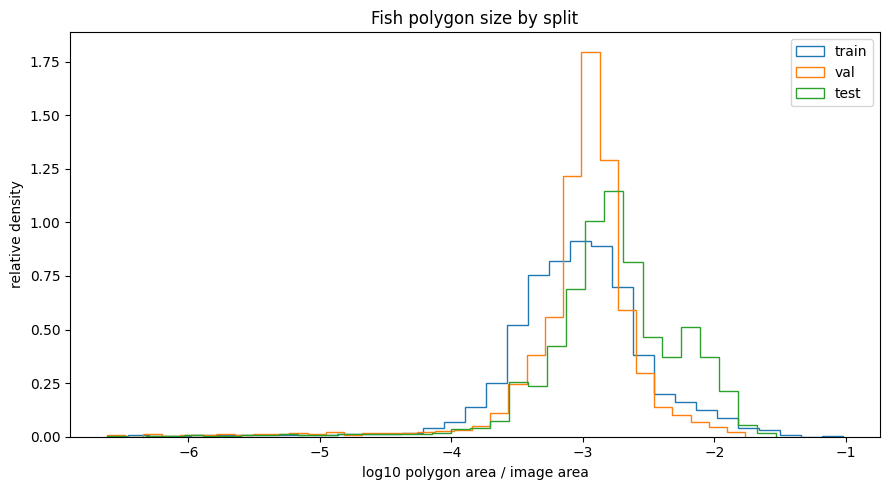

In [5]:
def poly_coords(line):
    a=np.fromstring(line.strip(),sep=' ')
    if len(a)<7 or len(a)%2!=1 or a[0]!=0 or not np.isfinite(a).all():return None
    xy=a[1:].reshape(-1,2)
    if np.any(xy<0) or np.any(xy>1):return None
    return xy

def polygon_area_fraction(xy):
    if xy is None:return 0.0
    return float(abs(np.sum(xy[:,0]*np.roll(xy[:,1],-1)-xy[:,1]*np.roll(xy[:,0],-1)))*0.5)

def area_bucket(a):
    if a<0.0025:return 'tiny (<0.25% image)'
    if a<0.02:return 'medium (0.25%-2%)'
    return 'large (>=2%)'
size_rows=[]
invalid_lines=0
for split in ('train','val','test'):
    for lab in sorted((DATA_ROOT/'labels'/split).glob('*.txt')):
        video=lab.stem.split('_')[0]
        for line in lab.read_text(encoding='utf-8-sig').splitlines():
            if not line.strip():continue
            xy=poly_coords(line)
            if xy is None:invalid_lines+=1;continue
            a=polygon_area_fraction(xy)
            size_rows.append({'split':split,'video':video,'area_fraction':a,'size_bucket':area_bucket(a)})
assert invalid_lines==0,f'Invalid label lines: {invalid_lines}'
print('Total polygon instances:',len(size_rows))
for split in ('train','val','test'):
    rows=[r for r in size_rows if r['split']==split]
    print(split,'instances=',len(rows),'size bins=',dict(Counter(r['size_bucket'] for r in rows)))
fig,ax=plt.subplots(figsize=(9,5))
for split in ('train','val','test'):
    vals=np.array([r['area_fraction'] for r in size_rows if r['split']==split]);vals=vals[vals>0]
    ax.hist(np.log10(vals),bins=35,histtype='step',label=split,density=True)
ax.set(xlabel='log10 polygon area / image area',ylabel='relative density',title='Fish polygon size by split')
ax.legend();fig.tight_layout();fig.savefig(OUT/'object_size_distribution.png',dpi=140);plt.show();plt.close(fig)
with (OUT/'object_size_distribution.csv').open('w',newline='',encoding='utf-8') as f:
    w=csv.DictWriter(f,fieldnames=['split','video','area_fraction','size_bucket']);w.writeheader();w.writerows(size_rows)

## 5 — Inference and instance matching (without training)

Run YOLO **once** at low confidence on a small video-stratified subset. Each predicted instance is matched to one GT instance using greedy highest-mask-IoU matching. These are *diagnostic sample precision/recall at IoU≥0.5*, **NOT mAP**. Predicted masks are resized to a common 512×512 grid, as are YOLO polygons. This is an approximation used only for investigation. No score measured here is the official V11 reported mAP.

In [ ]:
SIZE=IMG_SIZE

def get_gt(path,split):
    label=DATA_ROOT/'labels'/split/(path.stem+'.txt')
    masks=[];areas=[]
    for line in label.read_text(encoding='utf-8-sig').splitlines():
        xy=poly_coords(line)
        if xy is None:continue
        arr=np.zeros((SIZE,SIZE),dtype=np.uint8)
        pts=np.rint(xy*np.array([SIZE-1,SIZE-1])).astype(np.int32)
        cv2.fillPoly(arr,[pts],1)
        masks.append(arr.astype(bool));areas.append(polygon_area_fraction(xy))
    return masks,areas

def get_preds(path):
    result=MODEL.predict(source=str(path),imgsz=IMG_SIZE,conf=CANDIDATE_CONF,
      iou=0.70,device=DEVICE,retina_masks=True,max_det=100,verbose=False)[0]
    confidences=[];masks=[]
    if result.boxes is not None and result.masks is not None:
        confidences=result.boxes.conf.detach().cpu().numpy().astype(float).tolist()
        masks_data=result.masks.data.detach().cpu().numpy()
        for mask in masks_data:
            # retval mask is produced at original image aspect ratio; resize only for diagnostic raster IoU.
            masks.append(cv2.resize((mask>0.5).astype(np.uint8),(SIZE,SIZE),interpolation=cv2.INTER_NEAREST).astype(bool))
    return confidences,masks

def match_masks(gt,pred,thr=MATCH_IOU):
    pairs=[]
    for i,g in enumerate(gt):
        ga=int(g.sum())
        for j,p in enumerate(pred):
            inter=np.logical_and(g,p).sum()
            union=ga+int(p.sum())-inter
            iou=float(inter/union) if union else 0.0
            if iou>=thr:pairs.append((iou,i,j))
    pairs.sort(reverse=True)
    used_g=set();used_p=set();matches=[]
    for iou,i,j in pairs:
        if i not in used_g and j not in used_p:
            used_g.add(i);used_p.add(j);matches.append((i,j,iou))
    return matches

records=[]
from tqdm.auto import tqdm
for split in ('val','test'):
    for path in tqdm(samples[split],desc=f'Inference {split}'):
        gt,areas=get_gt(path,split)
        conf,masks=get_preds(path)
        records.append({'split':split,'video':path.stem.split('_')[0],
           'image':path.name,'path':str(path),'gt':gt,'areas':areas,'conf':conf,'pred':masks})
print('Inference complete, frames:',len(records))

## 6 — Select confidence threshold on VALIDATION ONLY

This threshold search is for diagnostic error analysis, not to claim new mAP. The V11 official test results already exist and remain the primary published results.

In [ ]:
def score(records,threshold):
    summary=Counter();by_video=defaultdict(Counter);size_bin=defaultdict(Counter);frame_rows=[]
    for r in records:
        selected=[m for c,m in zip(r['conf'],r['pred']) if c>=threshold]
        matches=match_masks(r['gt'],selected)
        tp=len(matches);fn=len(r['gt'])-tp;fp=len(selected)-tp
        summary.update(tp=tp,fp=fp,fn=fn,frames=1)
        by_video[r['video']].update(tp=tp,fp=fp,fn=fn,frames=1)
        matched_idx={i for i,_,_ in matches}
        for i,a in enumerate(r['areas']):
            k=area_bucket(a)
            size_bin[k].update(gt=1,matched=int(i in matched_idx))
        frame_rows.append({'split':r['split'],'video':r['video'],'image':r['image'],
             'gt':len(r['gt']),'pred':len(selected),'tp':tp,'fp':fp,'fn':fn,
             'mean_gt_area_fraction':float(np.mean(r['areas'])) if r['areas'] else 0.0})
    tp,fp,fn=summary['tp'],summary['fp'],summary['fn']
    precision=tp/(tp+fp) if tp+fp else 0.0
    recall=tp/(tp+fn) if tp+fn else 0.0
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {'precision':precision,'recall':recall,'f1':f1,
       'tp':tp,'fp':fp,'fn':fn,'sampled_frames':summary['frames']},by_video,size_bin,frame_rows

validation_records=[r for r in records if r['split']=='val']
test_records=[r for r in records if r['split']=='test']
sweep={str(t):score(validation_records,t)[0] for t in THRESHOLDS}
BEST_CONF=max(THRESHOLDS,key=lambda t:(sweep[str(t)]['f1'],-t))
print('Validation confidence sweep (sampled, not mAP):')
print(json.dumps(sweep,indent=2))
print('Selected confidence from VAL ONLY:',BEST_CONF)
(OUT/'confidence_sweep_validation.json').write_text(json.dumps({'threshold_results':sweep,'selected_from_validation':BEST_CONF,'metric':'sample F1 IoU>=0.5; NOT mAP'},indent=2))

## 7 — Per-video, per-size and failure-case tables

Contrast **video-level** performance, false negatives and small-object recall on the sampled validation/test videos; these differences may explain the original validation/test gap. Note that the original test is no longer pristine after V11 evaluation; use findings for research hypotheses, not a fresh final score.

In [ ]:
ALL_RESULTS={};all_frame_rows=[];video_rows=[];bucket_rows=[]
for split,rr in [('val',validation_records),('test',test_records)]:
    headline,by_video,buckets,fr=score(rr,BEST_CONF)
    ALL_RESULTS[split]=headline
    all_frame_rows.extend(fr)
    for v,c in sorted(by_video.items()):
        tp,fp,fn=c['tp'],c['fp'],c['fn']
        video_rows.append({'split':split,'video':v,'frames':c['frames'],'gt':tp+fn,
           'tp':tp,'fp':fp,'fn':fn,'precision':tp/(tp+fp) if tp+fp else 0,
           'recall':tp/(tp+fn) if tp+fn else 0})
    for b,c in sorted(buckets.items()):
        bucket_rows.append({'split':split,'size_bucket':b,'gt_count':c['gt'],
            'matched':c['matched'],'recall':c['matched']/c['gt'] if c['gt'] else None})
print('Sample diagnostics (NOT official mAP):',json.dumps(ALL_RESULTS,indent=2))
for v in sorted(video_rows,key=lambda x:(x['split'],x['recall'])):
    print(f"{v['split']:4s} {v['video']:9s} n={v['frames']:2d} GT={v['gt']:3d} recall={v['recall']:.3f} FP={v['fp']}")
print('Size-bin recall:')
for x in bucket_rows:print(x)

def write_csv(name,rr):
    if not rr:return
    with (OUT/name).open('w',newline='',encoding='utf-8') as f:
        writer=csv.DictWriter(f,fieldnames=list(rr[0]));writer.writeheader();writer.writerows(rr)
write_csv('diagnostic_per_video.csv',video_rows)
write_csv('diagnostic_per_frame.csv',all_frame_rows)
write_csv('diagnostic_per_size.csv',bucket_rows)

## 8 — Graphs and real GT-vs-prediction overlays

Plot per-video recall, size-bin recall, and representative worst frames. **Green** = GT polygons, **red** = predicted instance masks. A correct overlay is qualitative evidence only; it is not proof of generalization.

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,split in zip(axes,['val','test']):
    rr=[r for r in video_rows if r['split']==split]
    ax.bar(range(len(rr)),[r['recall'] for r in rr]);ax.set_xticks(range(len(rr)))
    ax.set_xticklabels([r['video'] for r in rr],rotation=55,ha='right');ax.set_ylim(0,1)
    ax.set_title(f'{split} — sampled GT instance recall @ IoU 0.5')
    ax.set_ylabel('Recall')
fig.tight_layout();fig.savefig(OUT/'recall_per_video.png',dpi=150);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(10,5))
keys=sorted(set(r['size_bucket'] for r in bucket_rows))
x=np.arange(len(keys));width=.35
for offset,split in [(-width/2,'val'),(width/2,'test')]:
    vals=[next((r['recall'] for r in bucket_rows if r['split']==split and r['size_bucket']==key),0) for key in keys]
    ax.bar(x+offset,vals,width,label=split)
ax.set_xticks(x);ax.set_xticklabels(keys,rotation=10);ax.set_ylim(0,1)
ax.set_ylabel('GT mask matching recall');ax.set_title('Small-object diagnostic');ax.legend()
fig.tight_layout();fig.savefig(OUT/'recall_by_size.png',dpi=150);plt.show();plt.close(fig)

worst=sorted(all_frame_rows,key=lambda r:(-r['fn'],-r['fp'],r['tp']))[:MAX_OVERLAYS]
chosen={(r['split'],r['image']):r for r in records}
preview_dir=OUT/'overlays';preview_dir.mkdir(exist_ok=True)
for idx,entry in enumerate(worst):
    r=chosen[(entry['split'],entry['image'])]
    original=cv2.imread(r['path'])
    if original is None:continue
    original=cv2.resize(cv2.cvtColor(original,cv2.COLOR_BGR2RGB),(SIZE,SIZE))
    gt_overlay=original.copy();pred_overlay=original.copy()
    gtunion=np.zeros((SIZE,SIZE),bool);prunion=np.zeros((SIZE,SIZE),bool)
    for mask in r['gt']:gtunion|=mask
    for conf,mask in zip(r['conf'],r['pred']):
        if conf>=BEST_CONF:prunion|=mask
    gt_overlay[gtunion]=(0.45*gt_overlay[gtunion]+0.55*np.array([0,255,0])).astype(np.uint8)
    pred_overlay[prunion]=(0.45*pred_overlay[prunion]+0.55*np.array([255,0,0])).astype(np.uint8)
    view=np.concatenate([original,gt_overlay,pred_overlay],axis=1)
    cv2.imwrite(str(preview_dir/f"{idx:02d}_{entry['split']}_{Path(r['image']).stem}.jpg"),cv2.cvtColor(view,cv2.COLOR_RGB2BGR))
print('Saved overlays:',len(list(preview_dir.glob('*.jpg'))))
print('Side-by-side columns: original | ground truth (green) | predicted masks (red)')
fig,axes=plt.subplots(2,2,figsize=(14,7))
for ax,f in zip(axes.flat,sorted(preview_dir.glob('*.jpg'))[:4]):
    ax.imshow(cv2.cvtColor(cv2.imread(str(f)),cv2.COLOR_BGR2RGB));ax.set_title(f.name,fontsize=8);ax.axis('off')
for ax in axes.flat:ax.axis('off')
fig.tight_layout();plt.show();plt.close(fig)

## 9 — Reproducible report, checkpoint and compact ZIP

Write diagnostic metadata, keep original V11 full test metrics separate, and package the trained checkpoint **without retraining**. Check ZIP content and CRC. The original Kaggle inputs remain unchanged.

In [ ]:
sha=hashlib.sha256()
with WEIGHTS.open('rb') as f:
    for b in iter(lambda:f.read(1024*1024),b''):sha.update(b)
report={
 'status':'diagnostic_completed_no_training',
 'dataset_root':str(DATA_ROOT), 'v11_results_root':str(V11_INPUT),
 'weights_file':str(WEIGHTS),'weights_sha256':sha.hexdigest(),
 'v11_full_evaluation':{
   'validation_metrics':v11_report.get('validation_metrics'),
   'heldout_test_metrics':v11_report.get('heldout_test_metrics')},
 'sample_design':{'random_seed':SEED,'samples_per_video':SAMPLES_PER_VIDEO,'num_val_images':len(validation_records),
   'num_test_images':len(test_records),'instance_match_iou':MATCH_IOU,
   'raster_size':[SIZE,SIZE]},
 'validation_only_confidence_selection':{'threshold_candidates':THRESHOLDS,'selected':BEST_CONF},
 'sampled_diagnostic_metrics_NOT_mAP':ALL_RESULTS,
 'source_conversion_metadata':conversion,
 'warnings':[
  'NO TRAINING PERFORMED. These results are sampled precision/recall for mask matching at IoU>=0.5, not COCO mAP.',
  'This analysis uses prior held-out test data for exploratory diagnostics: the test set has already been evaluated in V11 and is not a fresh unseen test.',
  'Reported V11 official mAP is not replaced by the sampled diagnosis.',
  'The mask-matching procedure uses 512x512 raster rescaling and greedy matching; it is not the Ultralytics official validation implementation.',
  'Original annotation masks were converted to polygons with excluded frames; interpretation is limited to retained YOLO labels.',
  'Video-disjoint does not imply distinct fish identities across video recordings.',
  'No fish length in centimetres or calibrated stereo geometry is evaluated.']}
(OUT/'diagnostic_report.json').write_text(json.dumps(report,indent=2,default=str),encoding='utf-8')
(OUT/'README.md').write_text("""# FishSizeEstimate V12 — Diagnostic outputs (no training)

* `diagnostic_report.json`: V11 official metrics vs V12 sampled analysis (not mAP).
* `diagnostic_per_video.csv`, `diagnostic_per_frame.csv`, `diagnostic_per_size.csv`: error analysis.
* `confidence_sweep_validation.json`: threshold selected only from sampled validation.
* `object_size_distribution.*`: polygon-area distributions.
* `recall_per_video.png`, `recall_by_size.png`: diagnostic plots.
* `overlays/`: original / GT / model masks side by side.
* `models/best_fish_segmenter.pt`: exact copy of V11 trained weights.

No new training, no proof of physical length estimation. The official V11 held-out evaluation remains authoritative for model performance on that particular test set.
""",encoding='utf-8')
model_dir=OUT/'models';model_dir.mkdir(exist_ok=True)
shutil.copy2(WEIGHTS,model_dir/'best_fish_segmenter.pt')
ZIP=Path('/kaggle/working/FishSizeEstimate_V12_Diagnostics.zip')
with zipfile.ZipFile(ZIP,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as z:
    for f in sorted(OUT.rglob('*')):
        if f.is_file():z.write(f,f.relative_to(OUT).as_posix())
with zipfile.ZipFile(ZIP) as z:
    bad=z.testzip()
    assert bad is None,f'CRC error: {bad}'
    assert 'models/best_fish_segmenter.pt' in z.namelist()
    assert 'diagnostic_report.json' in z.namelist()
print('DONE — NO TRAINING')
print('ZIP:',ZIP,'size MiB:',round(ZIP.stat().st_size/1024**2,2))
print('Best checkpoint:',model_dir/'best_fish_segmenter.pt')
print('Sampled diagnostic metrics, NOT mAP:',json.dumps(ALL_RESULTS,indent=2))
print('V11 authoritative held-out metrics:',json.dumps(v11_report.get('heldout_test_metrics','UNAVAILABLE'),indent=2))

## Interpretation checklist

- Did mask polygons overlap visible fish, or include background? Inspect `overlays/`.
- Is small-object recall much lower than medium/large? If yes, **hypothesis:** resolution / small targets; test later in a controlled experiment.
- Are some video groups much harder? If yes, **hypothesis:** domain shift (scene density, lighting, species, camera); evaluate domain-specific failures.
- Is model precision high but recall low? **Hypothesis:** model conservatism or missing small instances; confidence selected from validation only is a diagnostic choice.
- Was V11 full-set test unexpectedly better than validation? Sampled per-video results may reveal distribution differences, **not proof of leakage**.

**DO NOT start V13 training automatically**. Reassess labels and real overlays first; implement a controlled model/data experiment only when backed by evidence.

References: [Ultralytics predict mode](https://docs.ultralytics.com/modes/predict), [Ultralytics validation mode](https://docs.ultralytics.com/modes/val).